# Early Warning System (EWS) Siswa Berisiko - Moodle OULAD
Prediksi siswa berisiko drop atau gagal dari log keaktifan dan pengumpulan tugas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Load Data OULAD
student_info = pd.read_csv('studentInfo.csv')
student_vle = pd.read_csv('studentVle.csv')
student_assessment = pd.read_csv('studentAssessment.csv')
assessments = pd.read_csv('assessments.csv')

print("Ukuran Data Awal:")
print(f"- Data Siswa & Status: {student_info.shape[0]:,} baris")
print(f"- Log Interaksi VLE:   {student_vle.shape[0]:,} baris")
print(f"- Nilai Asesmen Siswa: {student_assessment.shape[0]:,} baris")
print(f"- Jadwal Asesmen:      {assessments.shape[0]:,} baris")

Ukuran Data Awal:
- Data Siswa & Status: 32,593 baris
- Log Interaksi VLE:   10,655,280 baris
- Nilai Asesmen Siswa: 173,912 baris
- Jadwal Asesmen:      206 baris


## 1. Filter Cut-Off Hari ke-60
Batasi data hingga hari ke-60 untuk deteksi dini.

In [2]:
CUT_OFF_DAY = 60

# 1. Filter log VLE sampai hari ke-60
vle_early = student_vle[student_vle['date'] <= CUT_OFF_DAY].copy()

# 2. Gabungkan asesmen dengan jadwal deadline
assessment_merged = pd.merge(student_assessment, assessments, on='id_assessment')

# 3. Filter asesmen yang tenggat waktunya ada sebelum/sampai hari ke-60
assessment_early = assessment_merged[assessment_merged['date'] <= CUT_OFF_DAY].copy()

print(f"Log VLE dalam batas cut-off (<= day {CUT_OFF_DAY}): {vle_early.shape[0]:,} baris")
print(f"Asesmen dalam batas cut-off (<= day {CUT_OFF_DAY}): {assessment_early.shape[0]:,} baris")

Log VLE dalam batas cut-off (<= day 60): 4,499,256 baris
Asesmen dalam batas cut-off (<= day 60): 47,259 baris


## 2. Feature Engineering
Agregasi log klik, kepatuhan tugas, dan nilai per modul siswa.

In [3]:
# ==========================================
# A. INDIKATOR KEAKTIFAN & PERILAKU VLE
# ==========================================
vle_features = vle_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique'),
    last_active_date=('date', 'max')
).reset_index()

# Hitung hari inaktif (jarak dari aktivitas terakhir ke hari cut-off)
vle_features['days_inactive'] = CUT_OFF_DAY - vle_features['last_active_date']
vle_features.drop(columns=['last_active_date'], inplace=True)

# ==========================================
# B. INDIKATOR KEPATUHAN & NILAI ASESMEN
# ==========================================
assessment_early['is_late'] = assessment_early['date_submitted'] > assessment_early['date']
assessment_early['submission_gap'] = assessment_early['date_submitted'] - assessment_early['date']

assessment_features = assessment_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    tasks_submitted=('id_assessment', 'count'),
    late_submission_count=('is_late', 'sum'),
    avg_submission_gap=('submission_gap', 'mean'),
    avg_score=('score', 'mean'),
    min_score=('score', 'min')
).reset_index()

# Hitung jumlah asesmen yang seharusnya sudah dikumpulkan per mata pelajaran & semester
tasks_due_per_course = assessments[assessments['date'] <= CUT_OFF_DAY].groupby(
    ['code_module', 'code_presentation']
)['id_assessment'].nunique().reset_index(name='total_tasks_due')

# ==========================================
# C. MERGE FITUR KE DATA UTAMA
# ==========================================
base_cols = ['code_module', 'code_presentation', 'id_student', 'final_result']
df_final = pd.merge(student_info[base_cols], vle_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_final = pd.merge(df_final, assessment_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_final = pd.merge(df_final, tasks_due_per_course, on=['code_module', 'code_presentation'], how='left')

# Imputasi nilai kosong yang logis (siswa belum pernah klik / belum pernah kumpul tugas)
df_final['total_tasks_due'] = df_final['total_tasks_due'].fillna(0)
df_final['tasks_submitted'] = df_final['tasks_submitted'].fillna(0)
df_final['missing_assignments'] = np.maximum(0, df_final['total_tasks_due'] - df_final['tasks_submitted'])
df_final['total_clicks'] = df_final['total_clicks'].fillna(0)
df_final['active_days'] = df_final['active_days'].fillna(0)
df_final['days_inactive'] = df_final['days_inactive'].fillna(CUT_OFF_DAY)
df_final['late_submission_count'] = df_final['late_submission_count'].fillna(0)
df_final['avg_submission_gap'] = df_final['avg_submission_gap'].fillna(0)
df_final['avg_score'] = df_final['avg_score'].fillna(0)
df_final['min_score'] = df_final['min_score'].fillna(0)

# Target: 1 = Berisiko (Fail / Withdrawn), 0 = Aman (Pass / Distinction)
df_final['is_at_risk'] = df_final['final_result'].apply(lambda x: 1 if x in ['Fail', 'Withdrawn'] else 0)

print("Dataset Siap untuk Modeling:")
print(f"Total baris: {len(df_final):,}")
print(f"Proporsi Siswa Berisiko: {df_final['is_at_risk'].mean():.2%}")

Dataset Siap untuk Modeling:
Total baris: 32,593
Proporsi Siswa Berisiko: 52.80%


## 3. Split Cohort (Train: 2013, Test: 2014)
Validasi model menggunakan data tahun berikutnya.

In [4]:
feature_cols = [
    'total_clicks', 
    'active_days', 
    'days_inactive', 
    'missing_assignments', 
    'late_submission_count', 
    'avg_submission_gap', 
    'avg_score', 
    'min_score'
]

# Split berbasis kohor tahun ajaran
train_mask = df_final['code_presentation'].str.startswith('2013')
test_mask = df_final['code_presentation'].str.startswith('2014')

X_train, y_train = df_final.loc[train_mask, feature_cols], df_final.loc[train_mask, 'is_at_risk']
X_test, y_test = df_final.loc[test_mask, feature_cols], df_final.loc[test_mask, 'is_at_risk']

print(f"Jumlah Data Latih (Kohor 2013): {len(X_train):,} siswa")
print(f"Jumlah Data Uji (Kohor 2014):   {len(X_test):,} siswa")

Jumlah Data Latih (Kohor 2013): 13,529 siswa
Jumlah Data Uji (Kohor 2014):   19,064 siswa


## 4. Training Random Forest

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=7,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
print("Model Random Forest berhasil dilatih pada kohor 2013!")

Model Random Forest berhasil dilatih pada kohor 2013!


## 5. Evaluasi Data Test 2014

=== LAPORAN EVALUASI OUT-OF-COHORT (TEST 2014 - DEFAULT THRESHOLD 0.50) ===
              precision    recall  f1-score   support

    Aman (0)       0.74      0.82      0.78      8815
Berisiko (1)       0.83      0.75      0.79     10249

    accuracy                           0.78     19064
   macro avg       0.78      0.78      0.78     19064
weighted avg       0.79      0.78      0.78     19064

ROC-AUC Score: 0.8713


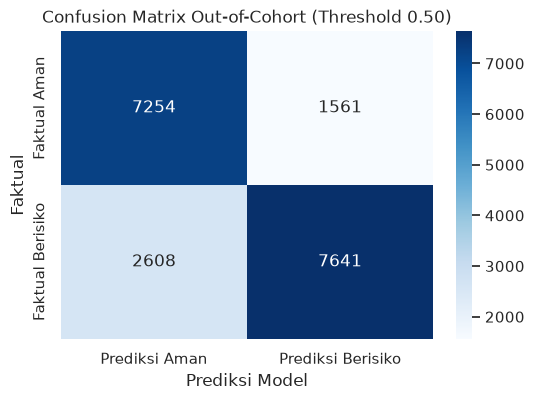

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred_default = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("=== LAPORAN EVALUASI OUT-OF-COHORT (TEST 2014 - DEFAULT THRESHOLD 0.50) ===")
print(classification_report(y_test, y_pred_default, target_names=['Aman (0)', 'Berisiko (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_default)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Prediksi Aman', 'Prediksi Berisiko'],
            yticklabels=['Faktual Aman', 'Faktual Berisiko'])
plt.title('Confusion Matrix Out-of-Cohort (Threshold 0.50)')
plt.ylabel('Faktual')
plt.xlabel('Prediksi Model')
plt.show()

## 6. Kalibrasi Threshold

In [7]:
from sklearn.metrics import precision_recall_fscore_support

print("Evaluasi Trade-off Threshold untuk Sistem EWS BK:")
print("-" * 58)
print(f"{'Threshold':<10} | {'Precision (1)':<15} | {'Recall (1)':<15} | {'F1-Score'}")
print("-" * 58)

for th in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    yp = (y_prob >= th).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test, yp, average=None)
    flag = " [Rekomendasi]" if th == 0.40 else ""
    print(f"{th:<10.2f} | {p[1]:<15.2%} | {r[1]:<15.2%} | {f[1]:.4f}{flag}")

# Terapkan Threshold Terpilih (0.40)
OPTIMAL_THRESHOLD = 0.40
y_pred_calibrated = (y_prob >= OPTIMAL_THRESHOLD).astype(int)
print(f"\n=== HASIL SETELAH KALIBRASI THRESHOLD {OPTIMAL_THRESHOLD:.2f} ===")
print(classification_report(y_test, y_pred_calibrated, target_names=['Aman (0)', 'Berisiko (1)']))

Evaluasi Trade-off Threshold untuk Sistem EWS BK:
----------------------------------------------------------
Threshold  | Precision (1)   | Recall (1)      | F1-Score
----------------------------------------------------------
0.35       | 76.31%          | 83.49%          | 0.7974
0.40       | 78.85%          | 80.70%          | 0.7976 [Rekomendasi]
0.45       | 81.31%          | 77.41%          | 0.7931
0.50       | 83.04%          | 74.55%          | 0.7857
0.55       | 87.32%          | 71.04%          | 0.7835
0.60       | 89.56%          | 67.63%          | 0.7706

=== HASIL SETELAH KALIBRASI THRESHOLD 0.40 ===
              precision    recall  f1-score   support

    Aman (0)       0.77      0.75      0.76      8815
Berisiko (1)       0.79      0.81      0.80     10249

    accuracy                           0.78     19064
   macro avg       0.78      0.78      0.78     19064
weighted avg       0.78      0.78      0.78     19064



## 7. Feature Importance & Simpan Model

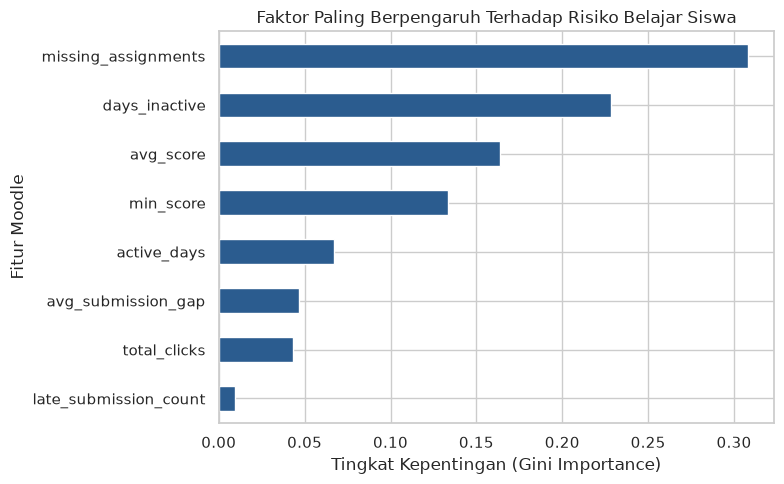

Model dan metadata berhasil disimpan ke 'ews_moodle_model.pkl'!


In [8]:
importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#2b5c8f')
plt.title('Faktor Paling Berpengaruh Terhadap Risiko Belajar Siswa')
plt.xlabel('Tingkat Kepentingan (Gini Importance)')
plt.ylabel('Fitur Moodle')
plt.tight_layout()
plt.show()

# Simpan model beserta metadata
joblib.dump({
    'model': rf_model,
    'features': feature_cols,
    'optimal_threshold': OPTIMAL_THRESHOLD,
    'cut_off_day': CUT_OFF_DAY
}, 'ews_moodle_model.pkl')

print("Model dan metadata berhasil disimpan ke 'ews_moodle_model.pkl'!")

## 8. Generator Payload JSON untuk AI SLM & Integrasi WhatsApp
Bagian ini bertindak sebagai jembatan antara model prediksi tabular (*Random Forest*) dan **AI SLM (*Small Language Model*)**.
Model EWS menghasilkan data fakta terstruktur dalam format **JSON**, yang kemudian diparsing ke SLM (seperti LLaMA 3.2, Qwen 2.5, Phi-3.5) untuk digenerate menjadi draf pesan WhatsApp yang empatik, kontekstual, dan personal.


In [9]:
import json

def generate_ews_json(student_row, probability, threshold=0.40, as_string=True):
    """
    Menghasilkan payload JSON terstruktur dari hasil deteksi EWS
    untuk diparsing ke AI SLM (Small Language Model) guna pembuatan pesan WhatsApp.
    """
    if probability >= 0.70:
        risk_level = "TINGGI"
        urgency = "Tinggi (butuh intervensi/pemanggilan langsung dalam minggu ini)"
    elif probability >= threshold:
        risk_level = "SEDANG"
        urgency = "Sedang (disarankan pemantauan aktif dan konfirmasi santai)"
    else:
        risk_level = "RENDAH"
        urgency = "Rendah (aktivitas belajar masih aman dan terkontrol)"

    # Identifikasi pemicu risiko spesifik
    triggers = []
    if student_row['days_inactive'] >= 14:
        triggers.append(f"Tidak aktif di Moodle selama {int(student_row['days_inactive'])} hari berturut-turut.")
    if student_row['missing_assignments'] > 0:
        triggers.append(f"Ada {int(student_row['missing_assignments'])} tugas/kuis yang belum dikumpulkan.")
    if student_row['avg_score'] < 50 and student_row['tasks_submitted'] > 0:
        triggers.append(f"Rata-rata nilai kuis di bawah standar ({student_row['avg_score']:.1f}/100).")
    if student_row['late_submission_count'] > 0:
        triggers.append(f"Tercatat {int(student_row['late_submission_count'])} kali mengumpulkan tugas terlambat.")
    if student_row['total_clicks'] < 50:
        triggers.append(f"Frekuensi akses materi sangat minim (hanya {int(student_row['total_clicks'])} klik).")

    if not triggers:
        triggers.append("Pola interaksi umum menunjukkan penurunan keterlibatan belajar.")

    payload = {
        "student_profile": {
            "id_student": int(student_row['id_student']),
            "code_module": str(student_row['code_module']),
            "code_presentation": str(student_row['code_presentation'])
        },
        "risk_assessment": {
            "risk_level": risk_level,
            "risk_probability": round(float(probability), 4),
            "risk_percentage": f"{probability:.1%}",
            "decision_threshold": threshold,
            "needs_intervention": bool(probability >= threshold),
            "intervention_urgency": urgency
        },
        "moodle_behavior_metrics": {
            "days_inactive": int(student_row['days_inactive']),
            "total_clicks": int(student_row['total_clicks']),
            "active_days": int(student_row['active_days']),
            "missing_assignments": int(student_row['missing_assignments']),
            "tasks_submitted": int(student_row['tasks_submitted']),
            "late_submission_count": int(student_row['late_submission_count']),
            "avg_score": round(float(student_row['avg_score']), 1)
        },
        "detected_risk_factors": triggers
    }

    if as_string:
        return json.dumps(payload, indent=2, ensure_ascii=False)
    return payload


def create_slm_prompt(ews_json_str, audience="guru_bk"):
    """
    Menyusun prompt siap pakai untuk AI SLM (Ollama / vLLM / API).
    Pilihan audience: 'guru_bk', 'siswa', atau 'orang_tua'.
    """
    audience_guides = {
        "guru_bk": "Gaya bahasa profesional dan ringkas untuk Guru BK/Wali Kelas, memuat data pemicu risiko dan rekomendasi tindak lanjut.",
        "siswa": "Gaya bahasa santai, ramah, dan suportif langsung ke Siswa, mengajak diskusi/konseling tanpa menghakimi.",
        "orang_tua": "Gaya bahasa santun dan hormat untuk Orang Tua, mengajak bersinergi mendampingi belajar siswa di rumah."
    }

    prompt = f"""[SYSTEM PROMPT]
Anda adalah asisten AI sistem Early Warning System (EWS) bimbingan konseling dan akademik sekolah.
Tugas Anda adalah membaca data JSON hasil analisis risiko belajar siswa, lalu menuliskan draf pesan WhatsApp.

Aturan Penting:
1. HANYA gunakan fakta dari data JSON (JANGAN berhalusinasi mengarang nilai atau angka yang tidak ada).
2. Target Penerima: {audience.upper()} ({audience_guides.get(audience, audience_guides['guru_bk'])}).
3. Gunakan formatting WhatsApp (*bold*, poin bullet, emoji relevan).

[DATA SISWA (JSON)]
{ews_json_str}

[INSTRUKSI]
Buatkan draf pesan WhatsApp berdasarkan data di atas!
"""
    return prompt


# Fallback / Template statis (Rule-based) jika tanpa SLM
def generate_wa_notification(student_row, probability, threshold=0.40):
    """
    Menghasilkan draf notifikasi WhatsApp berbasis template statis (rule-based).
    """
    if probability >= 0.70:
        level_str = "⚠️ TINGGI"
        urgensi = "Siswa butuh intervensi/pemanggilan langsung dalam minggu ini."
    elif probability >= threshold:
        level_str = "🟡 SEDANG"
        urgensi = "Disarankan pemantauan aktif dan konfirmasi santai ke siswa."
    else:
        level_str = "🟢 RENDAH"
        urgensi = "Aktivitas belajar masih terpantau aman dan terkontrol."

    triggers = []
    if student_row['days_inactive'] >= 14:
        triggers.append(f"• Tidak aktif di Moodle selama {int(student_row['days_inactive'])} hari berturut-turut.")
    if student_row['missing_assignments'] > 0:
        triggers.append(f"• Ada {int(student_row['missing_assignments'])} tugas/kuis yang belum dikumpulkan.")
    if student_row['avg_score'] < 50 and student_row['tasks_submitted'] > 0:
        triggers.append(f"• Rata-rata nilai kuis di bawah standar ({student_row['avg_score']:.1f}).")
    if student_row['late_submission_count'] > 0:
        triggers.append(f"• Tercatat {int(student_row['late_submission_count'])} kali mengumpulkan tugas terlambat.")
    if student_row['total_clicks'] < 50:
        triggers.append(f"• Frekuensi akses materi sangat minim (hanya {int(student_row['total_clicks'])} klik).")

    if not triggers:
        triggers.append("• Pola interaksi umum menunjukkan penurunan keterlibatan belajar.")

    trigger_text = "\n".join(triggers)

    pesan = f"""*SISTEM PERINGATAN DINI (EWS) - BIMBINGAN KONSELING*
--------------------------------------------------
*Pemberitahuan Deteksi Risiko Belajar Siswa*

Kepada Yth. Bapak/Ibu Guru BK / Wali Kelas,
Sistem mendeteksi adanya indikasi kendala belajar pada siswa berikut:

👤 *ID Siswa*: {student_row['id_student']}
📚 *Mata Pelajaran*: {student_row['code_module']} ({student_row['code_presentation']})
📊 *Tingkat Risiko*: {level_str} (Probabilitas Risiko: {probability:.1%})

*Faktor Pemicu Risiko (Perilaku Moodle):*
{trigger_text}

*Rekomendasi Tindakan BK:*
{urgensi}

_Pesan otomatis Sistem EWS Moodle AI._
--------------------------------------------------"""
    return pesan


# ==========================================================
# PENGUJIAN: Ekstraksi Sampel Siswa Berisiko Tinggi
# ==========================================================
sample_risk_idx = y_test[y_test == 1].index[0]
sample_student = df_final.loc[sample_risk_idx]
sample_prob = y_prob[X_test.index.get_loc(sample_risk_idx)]

print("=" * 60)
print("1. OUTPUT JSON UNTUK DIPARSING KE AI SLM:")
print("=" * 60)
ews_json_output = generate_ews_json(sample_student, sample_prob, threshold=OPTIMAL_THRESHOLD)
print(ews_json_output)

print("\n" + "=" * 60)
print("2. CONTOH PROMPT UNTUK SLM (AUDIENCE: GURU BK):")
print("=" * 60)
prompt_bk = create_slm_prompt(ews_json_output, audience="guru_bk")
print(prompt_bk)

print("\n" + "=" * 60)
print("3. TEMPLATE STATIS (RULE-BASED SEBAGAI FALLBACK):")
print("=" * 60)
wa_message = generate_wa_notification(sample_student, sample_prob, threshold=OPTIMAL_THRESHOLD)
print(wa_message)


1. OUTPUT JSON UNTUK DIPARSING KE AI SLM:
{
  "student_profile": {
    "id_student": 65002,
    "code_module": "AAA",
    "code_presentation": "2014J"
  },
  "risk_assessment": {
    "risk_level": "TINGGI",
    "risk_probability": 0.7189,
    "risk_percentage": "71.9%",
    "decision_threshold": 0.4,
    "needs_intervention": true,
    "intervention_urgency": "Tinggi (butuh intervensi/pemanggilan langsung dalam minggu ini)"
  },
  "moodle_behavior_metrics": {
    "days_inactive": 50,
    "total_clicks": 3,
    "active_days": 1,
    "missing_assignments": 0,
    "tasks_submitted": 2,
    "late_submission_count": 0,
    "avg_score": 67.0
  },
  "detected_risk_factors": [
    "Tidak aktif di Moodle selama 50 hari berturut-turut.",
    "Frekuensi akses materi sangat minim (hanya 3 klik)."
  ]
}

2. CONTOH PROMPT UNTUK SLM (AUDIENCE: GURU BK):
[SYSTEM PROMPT]
Anda adalah asisten AI sistem Early Warning System (EWS) bimbingan konseling dan akademik sekolah.
Tugas Anda adalah membaca data JSO